# Q1. Which brain area has the lowest firing rate over the entire recording?

**Measure.** For each unit: rate = (number of spikes in the recording) / (recording length). The recording runs from 0 s to the end of the LFP (n_samples / 500 Hz).
Spikes outside that span are not counted. Only mouse 2 has some (1723 spikes before 0 s), plus a single spike in mouse 12.

**Inclusion.** All 1449 units are included, since none has zero spikes.

**Statistics.** Units are nested in mice, so the 1449 units are not 1449 independent samples. Two things handle that:
- a **hierarchical bootstrap**, which resamples mice and then units within each mouse, gives the 95% CIs of the mean and of the differences between areas;
- a **linear mixed model** on log10(rate), with a random intercept per mouse, serves as a second test that doesn't depend on the bootstrap.

The code lives in `c2p/q01_firing_rate.py` (the computation) and `c2p/stats.py` (the bootstrap). This notebook only plots and tests.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as sps

from c2p import AREAS, AREA_COLORS, RESULTS_DIR
from c2p import q01_firing_rate as q1
from c2p.stats import area_bootstrap, ci, lmm_pairwise

rates, tc = q1.compute()          # cached in results/; q1.compute(force=True) recomputes from the raw files
rates["log_rate"] = np.log10(rates.rate_hz)
print(f"{len(rates)} units from {rates.mouse.nunique()} mice")
rates.head()

1449 units from 18 mice


,mouse,cluster_id,area,n_spikes,n_spikes_outside,duration_s,rate_hz,log_rate
0,1,383,1,14747,0,3350.972,4.400813,0.643533
1,1,386,1,21102,0,3350.972,6.297277,0.799153
2,1,388,1,27012,0,3350.972,8.060945,0.906386
3,1,389,1,7535,0,3350.972,2.248601,0.351912
4,1,391,1,9683,0,3350.972,2.889609,0.460839


## 1. How many units per mouse and area

In [2]:
counts = rates.pivot_table(index="mouse", columns="area", values="cluster_id", aggfunc="size")
counts.T

mouse,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
area,,,,,,,,,,,,,,,,,,
1,59,40,47,34,59,33,39,33,52,23,16,19,69,18,14,56,24,14
2,22,20,26,6,57,24,29,32,32,5,38,12,29,10,33,37,44,22
3,7,19,12,17,13,10,25,25,49,13,19,11,16,16,15,7,36,12


## 2. Every unit

Firing rates are strongly skewed: most units fire a few spikes per second, and a few fire very fast.
So the left panel uses a log axis. The right panel shows the same data as distributions.
The black bar is the median, and the white diamond is the mean.

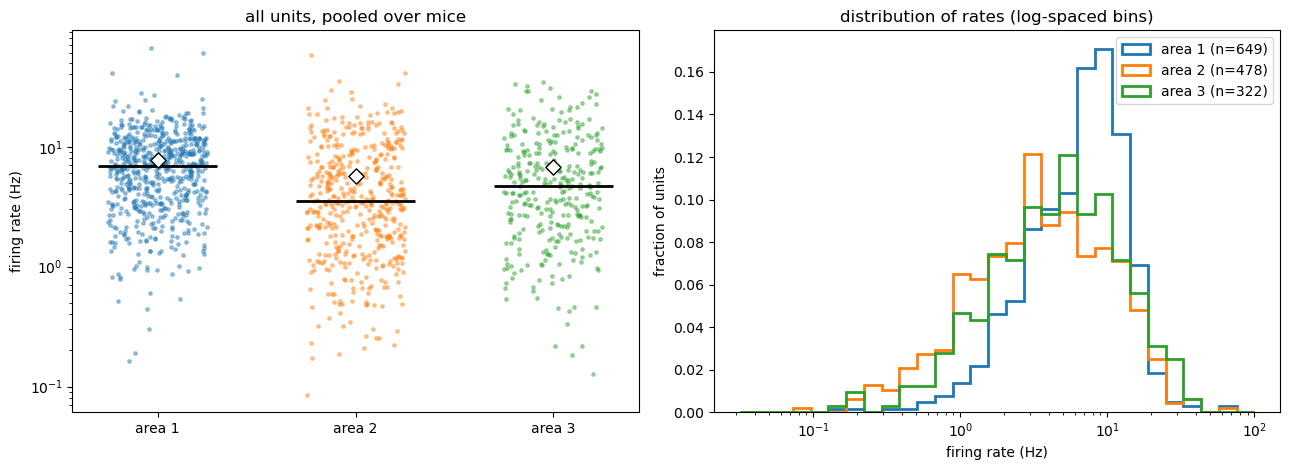

In [3]:
rng = np.random.default_rng(1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
for a in AREAS:
    r = rates.rate_hz[rates.area == a]
    a1.scatter(a + rng.uniform(-0.25, 0.25, len(r)), r, s=6, alpha=0.4, color=AREA_COLORS[a])
    a1.hlines(r.median(), a - 0.3, a + 0.3, color="k", lw=2)
    a1.scatter(a, r.mean(), marker="D", s=60, color="w", edgecolor="k", zorder=3)
    bins = np.logspace(-1.5, 2, 30)
    a2.hist(r, bins=bins, histtype="step", lw=2, color=AREA_COLORS[a], weights=np.full(len(r), 1 / len(r)),
            label=f"area {a} (n={len(r)})")
a1.set(yscale="log", xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS], ylabel="firing rate (Hz)",
       title="all units, pooled over mice")
a2.set(xscale="log", xlabel="firing rate (Hz)", ylabel="fraction of units", title="distribution of rates (log-spaced bins)")
a2.legend()
fig.tight_layout()

## 3. Mouse by mouse

Every mouse was recorded in all three areas, so each mouse can be compared with itself.
Each line is one mouse's mean rate per area. On the right is how often each area was the lowest one.

mouse,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
area,,,,,,,,,,,,,,,,,,
1,9.30,8.60,7.54,5.35,9.53,9.49,6.06,9.89,5.95,7.21,4.79,11.52,4.95,13.90,5.18,8.14,5.99,10.47
2,5.69,5.14,5.28,5.55,9.02,3.95,3.19,4.26,6.11,3.62,5.00,4.92,2.96,3.50,8.18,6.29,6.03,6.87
3,11.35,6.44,5.25,9.62,6.10,5.76,8.14,5.58,6.75,4.18,5.94,8.46,9.13,3.69,7.70,8.36,5.92,7.43


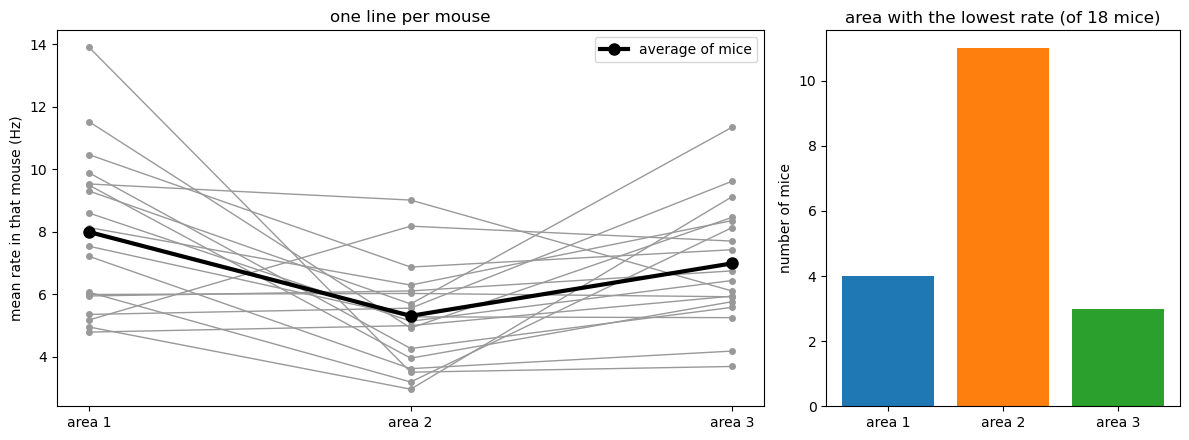

In [4]:
per_mouse = rates.groupby(["mouse", "area"]).rate_hz.mean().unstack()
lowest = per_mouse.idxmin(axis=1).value_counts().reindex(AREAS, fill_value=0)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw=dict(width_ratios=[2, 1]))
for m, row in per_mouse.iterrows():
    a1.plot(AREAS, row.values, "-o", color="0.6", ms=4, lw=1)
a1.plot(AREAS, per_mouse.mean().values, "-o", color="k", lw=3, ms=8, label="average of mice")
for a in AREAS:
    a1.plot([], [], "o", color=AREA_COLORS[a])
a1.set(xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS], ylabel="mean rate in that mouse (Hz)",
       title="one line per mouse")
a1.legend()
a2.bar([f"area {a}" for a in AREAS], lowest.values, color=[AREA_COLORS[a] for a in AREAS])
a2.set(ylabel="number of mice", title=f"area with the lowest rate (of {len(per_mouse)} mice)")
fig.tight_layout()
per_mouse.round(2).T

## 4. Mean and 95% CI (hierarchical bootstrap)

Each resample draws 18 mice with replacement. For each drawn mouse it then draws that mouse's units with replacement, separately per area.
Means and differences come from the same resamples, so the CI of a difference already accounts for the fact that areas share mice.

This is done twice:
- on the **rate (Hz)**: the arithmetic mean, which is what the questionnaire asks for;
- on **log10 rate**, back-transformed: the geometric mean. It's less driven by the few very fast units and serves as a robustness check.

In [5]:
PAIRS = [(2, 1), (2, 3), (3, 1)]       # "area x − area y"

t_lin, boot_lin = area_bootstrap(rates, "rate_hz", PAIRS)
t_log, boot_log = area_bootstrap(rates, "log_rate", PAIRS)
point_lin, point_log = t_lin.estimate.to_numpy(), t_log.estimate.to_numpy()
geo = (10 ** t_log.iloc[:3, :3]).rename(columns={"estimate": "geometric mean"})
print("Arithmetic mean (Hz):"); display(t_lin.round(3))
print("Geometric mean (Hz):"); display(geo.round(3))
print("Differences of log10 rate:"); display(t_log.iloc[3:].round(4))

Arithmetic mean (Hz):


,estimate,ci_low,ci_high,p (diff = 0)
area 1,7.779,6.714,8.895,NaN
area 2,5.729,4.576,6.840,NaN
area 3,6.772,5.861,7.814,NaN
area 2 − area 1,-2.049,-3.531,-0.802,0.002
area 2 − area 3,-1.042,-2.635,0.398,0.163
area 3 − area 1,-1.007,-2.685,0.635,0.230


Geometric mean (Hz):


,geometric mean,ci_low,ci_high
area 1,5.973,5.115,6.961
area 2,3.406,2.696,4.166
area 3,4.300,3.672,5.090


Differences of log10 rate:


,estimate,ci_low,ci_high,p (diff = 0)
area 2 − area 1,-0.2440,-0.3448,-0.1572,0.0000
area 2 − area 3,-0.1013,-0.2293,0.0095,0.0752
area 3 − area 1,-0.1427,-0.2480,-0.0358,0.0090


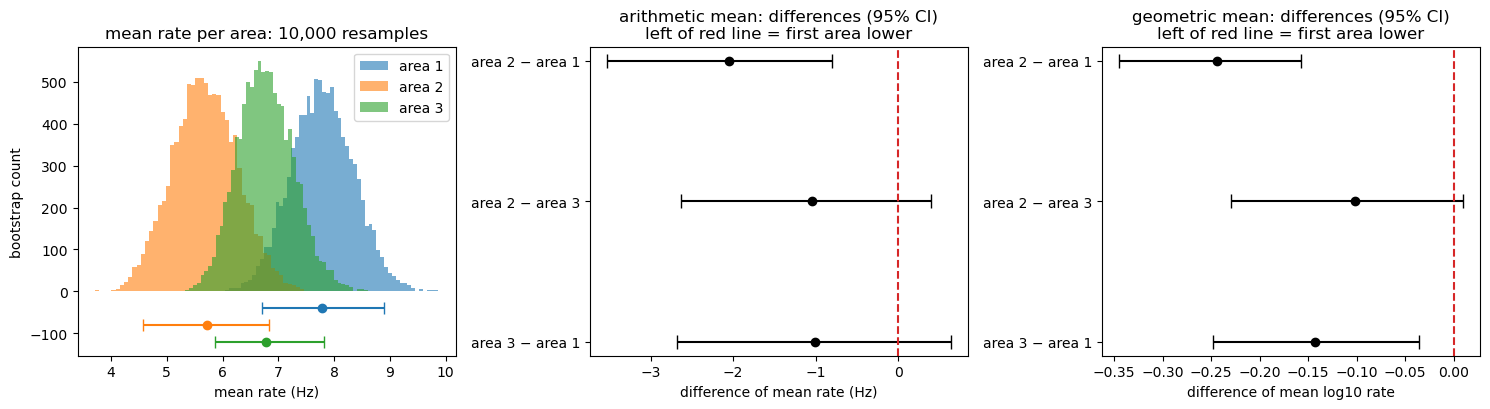

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for a in AREAS:
    k = a - 1
    axs[0].hist(boot_lin[:, k], bins=60, color=AREA_COLORS[a], alpha=0.6, label=f"area {a}")
    lo, hi = ci(boot_lin[:, k])
    axs[0].errorbar(point_lin[k], -40 * a, xerr=[[point_lin[k] - lo], [hi - point_lin[k]]],
                    fmt="o", color=AREA_COLORS[a], capsize=4)
axs[0].set(xlabel="mean rate (Hz)", ylabel="bootstrap count", title="mean rate per area: 10,000 resamples")
axs[0].legend()

for ax, boot, point, lab, ttl in [(axs[1], boot_lin, point_lin, "difference of mean rate (Hz)", "arithmetic mean"),
                                  (axs[2], boot_log, point_log, "difference of mean log10 rate", "geometric mean")]:
    for j, (x, y) in enumerate(PAIRS):
        k = 3 + j
        lo, hi = ci(boot[:, k])
        ax.errorbar(point[k], j, xerr=[[point[k] - lo], [hi - point[k]]], fmt="o", color="k", capsize=5)
    ax.axvline(0, color="tab:red", ls="--")
    ax.set(yticks=range(3), yticklabels=[f"area {x} − area {y}" for x, y in PAIRS], xlabel=lab,
           title=f"{ttl}: differences (95% CI)\nleft of red line = first area lower")
    ax.invert_yaxis()
fig.tight_layout()

## 5. Second test: linear mixed model

The model is `log10(rate) ~ area + (area | mouse)`. Each mouse gets its own baseline **and its own area differences**,
which is the honest version: the test of an area effect then has to beat how much that effect varies from mouse to mouse.
`lmm_pairwise` in `c2p/stats.py` fits it with each needed reference area, so all three pairwise differences appear as coefficients (log10 Hz).

In [7]:
lmm_tab = lmm_pairwise(rates, "log_rate", pairs=[(1, 2), (3, 2), (1, 3)])
lmm_tab["ratio of rates"] = 10 ** lmm_tab.coef
lmm_tab.round(4)

,coef,ci_low,ci_high,p,converged,p (Bonferroni),ratio of rates
contrast,,,,,,,
area 1 − area 2,0.2681,0.1797,0.3566,0.0000,True,0.0000,1.8541
area 3 − area 2,0.1258,0.0296,0.2219,0.0104,True,0.0312,1.3359
area 1 − area 3,0.1424,0.0506,0.2342,0.0024,True,0.0071,1.3879


And a third, very simple check that uses only the 18 per-mouse means (section 3):
a Friedman test across the three areas, then paired Wilcoxon tests.

In [8]:
print("Friedman:", sps.friedmanchisquare(*[per_mouse[a] for a in AREAS]))
for x, y in PAIRS:
    print(f"area {x} vs {y}: Wilcoxon", sps.wilcoxon(per_mouse[x], per_mouse[y]),
          f"| area {x} lower in {(per_mouse[x] < per_mouse[y]).sum()}/18 mice")

Friedman: FriedmanchisquareResult(statistic=np.float64(6.7777777777777715), pvalue=np.float64(0.03374615180055048))
area 2 vs 1: Wilcoxon WilcoxonResult(statistic=np.float64(20.0), pvalue=np.float64(0.0028076171875)) | area 2 lower in 13/18 mice
area 2 vs 3: Wilcoxon WilcoxonResult(statistic=np.float64(20.0), pvalue=np.float64(0.0028076171875)) | area 2 lower in 14/18 mice
area 3 vs 1: Wilcoxon WilcoxonResult(statistic=np.float64(60.0), pvalue=np.float64(0.28372955322265625)) | area 3 lower in 10/18 mice


## 6. Is it the same throughout the recording?

The question says "over the entire recording", so it's worth checking that the result isn't driven by one period.
The plot shows the mean rate per area in 1-minute bins, averaged over mice (±SEM across mice).
It stops at 54 minutes, the length of the shortest recording, so every point includes all 18 mice.

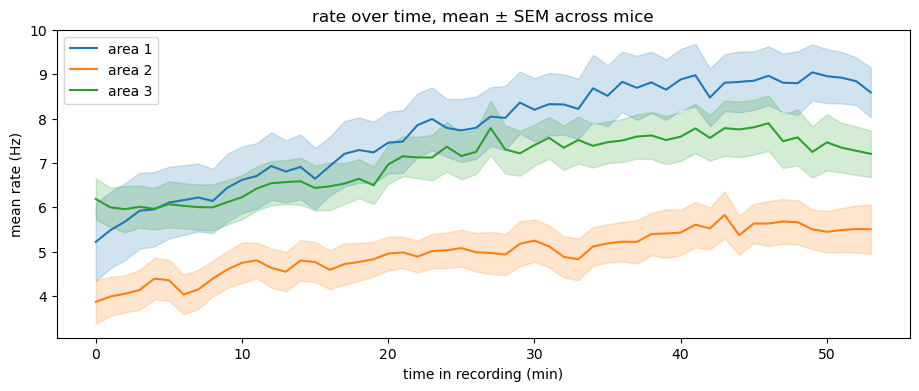

In [9]:
t_max = np.floor(rates.groupby("mouse").duration_s.first().min() / 60)
d = tc[tc.t_min < t_max]
fig, ax = plt.subplots(figsize=(11, 4))
for a in AREAS:
    g = d[d.area == a].groupby("t_min").rate_hz
    m, se = g.mean(), g.sem()
    ax.plot(m.index, m, color=AREA_COLORS[a], label=f"area {a}")
    ax.fill_between(m.index, m - se, m + se, color=AREA_COLORS[a], alpha=0.2)
ax.set(xlabel="time in recording (min)", ylabel="mean rate (Hz)", title="rate over time, mean ± SEM across mice")
ax.legend();

## 7. Answer for the questionnaire

In [10]:
answer = t_lin.iloc[:3, :3].copy()
answer.columns = ["Mean", "CI low", "CI high"]
answer["95% C.I."] = answer.apply(lambda r: f"[{r['CI low']:.2f}, {r['CI high']:.2f}]", axis=1)
answer["Units"] = "Hz (spikes/s)"
answer = answer[["Mean", "95% C.I.", "Units"]].round(2)
answer.to_csv(RESULTS_DIR / "q01_answer.csv")
answer

,Mean,95% C.I.,Units
area 1,7.78,"[6.71, 8.89]",Hz (spikes/s)
area 2,5.73,"[4.58, 6.84]",Hz (spikes/s)
area 3,6.77,"[5.86, 7.81]",Hz (spikes/s)


### Write it into the questionnaire

`record_answer` stores the answer in `results/answers.json`. Then `fill_pdf` rebuilds `docs/questionnaire_filled.pdf` from **all** stored answers,
so answers to earlier questions stay in it. The blank `docs/questionnaire.pdf` is never changed.

In [11]:
from c2p.questionnaire import fill_pdf, record_answer, record_meta

d = t_lin.loc
lm = lmm_tab["ratio of rates"]
lm_p = lmm_tab["p"]
n_out = rates.groupby("mouse").n_spikes_outside.sum()
w21 = min(1, 3 * sps.wilcoxon(per_mouse[2], per_mouse[1]).pvalue)   # Bonferroni, 3 comparisons
w23 = min(1, 3 * sps.wilcoxon(per_mouse[2], per_mouse[3]).pvalue)
explanation = (
    f"I computed each unit's firing rate as the number of its spikes within the recording divided by the "
    f"recording length (taken from the LFP), including all {len(rates)} units from the {rates.mouse.nunique()} mice; "
    f"the {n_out.sum()} spikes falling outside the recording were ignored. Because units recorded in the same mouse "
    f"are not independent, the mean of each area is reported with a hierarchical bootstrap CI, in which mice and then "
    f"units within each mouse were resampled 10,000 times. Area 2 fires less than area 1 by "
    f"{-d['area 2 − area 1', 'estimate']:.2f} Hz (95% CI {-d['area 2 − area 1', 'ci_high']:.2f} to "
    f"{-d['area 2 − area 1', 'ci_low']:.2f}). Its difference from area 3 ({-d['area 2 − area 3', 'estimate']:.2f} Hz) "
    f"is less clear on the arithmetic mean (CI {-d['area 2 − area 3', 'ci_high']:.2f} to "
    f"{-d['area 2 − area 3', 'ci_low']:.2f}), because firing rates are strongly skewed and a few very fast units "
    f"dominate it. I therefore also fitted a linear mixed model to log10 firing rate, with a random intercept and "
    f"random area effects for each mouse: area 3 fires {lm.iloc[1]:.2f} times faster than area 2 "
    f"(p = {min(1, 3 * lm_p.iloc[1]):.3f}) and area 1 {lm.iloc[0]:.2f} times faster (p < 0.001). Area 2 is also the lowest within "
    f"individual animals, being below area 3 in {(per_mouse[2] < per_mouse[3]).sum()} of 18 mice "
    f"(Wilcoxon p = {w23:.3f}) and below area 1 in {(per_mouse[2] < per_mouse[1]).sum()} (p = {w21:.3f}), and it "
    f"stays lowest throughout the recording. I therefore conclude that area 2 has the lowest firing rate."
)
explanation += " Pairwise p-values are Bonferroni-corrected for the three comparisons."
print(len(explanation.split()), "words")
record_answer(1, choice=1,                                   # 0 = area 1, 1 = area 2, 2 = area 3, 3 = not enough data
              rows=[(f"{r.Mean:.2f}", r["95% C.I."], r.Units) for _, r in answer.iterrows()],
              explanation=explanation)
record_meta(1, confidence=6, consensus=6)
print(fill_pdf())
print(explanation)

224 words


/home/dariosannino/con2phys/docs/questionnaire_filled.pdf
I computed each unit's firing rate as the number of its spikes within the recording divided by the recording length (taken from the LFP), including all 1449 units from the 18 mice; the 1724 spikes falling outside the recording were ignored. Because units recorded in the same mouse are not independent, the mean of each area is reported with a hierarchical bootstrap CI, in which mice and then units within each mouse were resampled 10,000 times. Area 2 fires less than area 1 by 2.05 Hz (95% CI 0.80 to 3.53). Its difference from area 3 (1.04 Hz) is less clear on the arithmetic mean (CI -0.40 to 2.63), because firing rates are strongly skewed and a few very fast units dominate it. I therefore also fitted a linear mixed model to log10 firing rate, with a random intercept and random area effects for each mouse: area 3 fires 1.34 times faster than area 2 (p = 0.031) and area 1 1.85 times faster (p < 0.001). Area 2 is also the lowest wit

## Conclusion

**Area 2 has the lowest firing rate.**

- Mean rate across units: area 2 is 5.7 Hz, area 3 is 6.8 Hz and area 1 is 7.8 Hz (hierarchical bootstrap CIs in the table above).
- Area 2 vs area 1 is clear in every analysis.
- Area 2 vs area 3 is the closer call. Several analyses favour area 2:
  - In each mouse, area 2 is below area 3 in 14 of 18 mice (Wilcoxon p ≈ 0.003).
  - The mixed model with mouse-specific area effects gives area 3 / area 2 ≈ 1.34× (p ≈ 0.01).
  - Area 2 stays lowest in every minute of the recording.
- On the other hand, the bootstrap CI of the *arithmetic* mean difference (2 − 3) includes 0. A few very fast units make the arithmetic mean noisy, and on the geometric mean the CI only just touches 0.

**Reporting.** The questionnaire asks for the mean, so the table reports the arithmetic mean with the hierarchical-bootstrap 95% CI, in Hz.
The explanation should mention the log-scale mixed model and the per-mouse comparison as the evidence for area 2 < area 3.